# 1.Import Libraries

In [1]:
!pip install nilearn nibabel

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow import keras
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.layers import Input ,BatchNormalization , Activation
from tensorflow.keras.layers import Conv2D, UpSampling2D
from tensorflow.keras.layers import MaxPooling2D
from tensorflow.keras.layers import concatenate
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras import optimizers
from sklearn.model_selection import train_test_split
import os
import nibabel as nib
import cv2 as cv
import matplotlib.pyplot as plt
from tensorflow.keras import backend as K
import glob
import skimage.io as io
import skimage.color as color
import random as r
import math
from nilearn import plotting

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


In [3]:
import kagglehub

Path = kagglehub.dataset_download(
    "sasikumarg/multiple-sclerosis-2016"
)

Using Colab cache for faster access to the 'multiple-sclerosis-2016' dataset.


# 2.Data Visualization

In [4]:
TRAIN_DATASET_PATH = Path

patient_path = os.path.join(
    TRAIN_DATASET_PATH,
    'MSSEG2016_TrainingData_Patient_02'
)

Flair = nib.load(os.path.join(
    patient_path,
    'MSSEG2016_TrainingData_Patient_02_FLAIR_preprocessed.nii'
))

Seg = nib.load(os.path.join(
    patient_path,
    'MSSEG2016_TrainingData_Patient_02_Consensus.nii'
))

T1 = nib.load(os.path.join(
    patient_path,
    'MSSEG2016_TrainingData_Patient_02_T1_preprocessed.nii'
))

T1ce = nib.load(os.path.join(
    patient_path,
    'MSSEG2016_TrainingData_Patient_02_DP_preprocessed.nii'
))

T2 = nib.load(os.path.join(
    patient_path,
    'MSSEG2016_TrainingData_Patient_02_T2_preprocessed.nii'
))

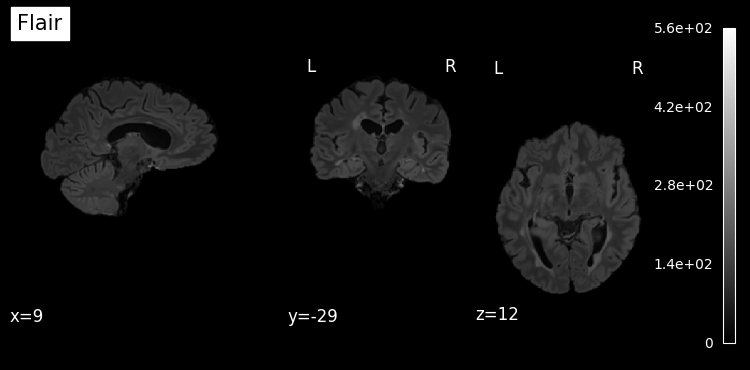

In [5]:
plotting.plot_anat(Flair,title="Flair",draw_cross =False)

/tmp/ipykernel_35885/969523008.py:1: UserWarning: Data array used to create a new image contains 64-bit ints. This is likely due to creating the array with numpy and passing `int` as the `dtype`. Many tools such as FSL and SPM cannot deal with int64 in Nifti images, so for compatibility the data has been converted to int32.
  plotting.plot_anat(Seg,title="Seg",draw_cross =False)


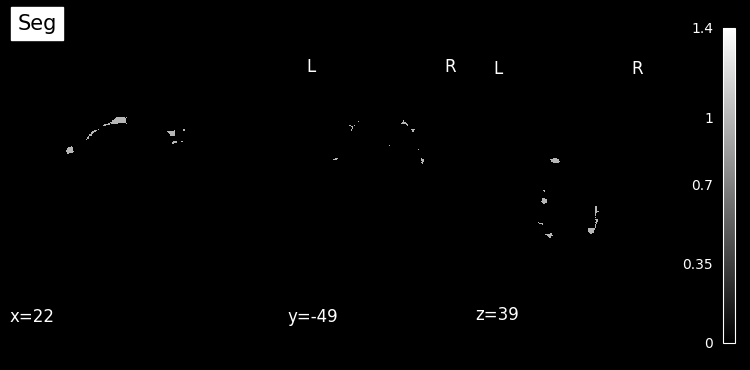

In [6]:
plotting.plot_anat(Seg,title="Seg",draw_cross =False)

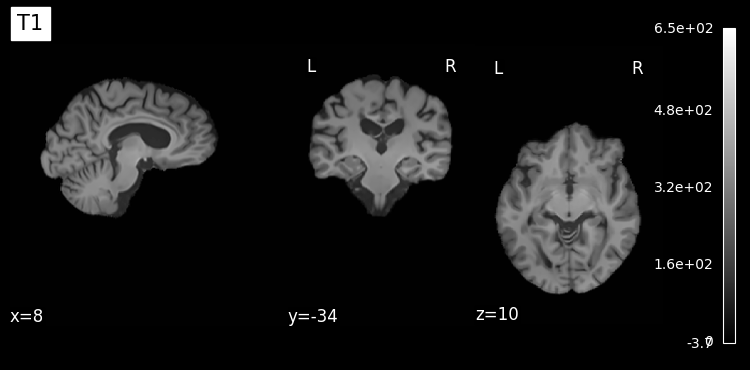

In [7]:
plotting.plot_anat(T1,title="T1",draw_cross =False)

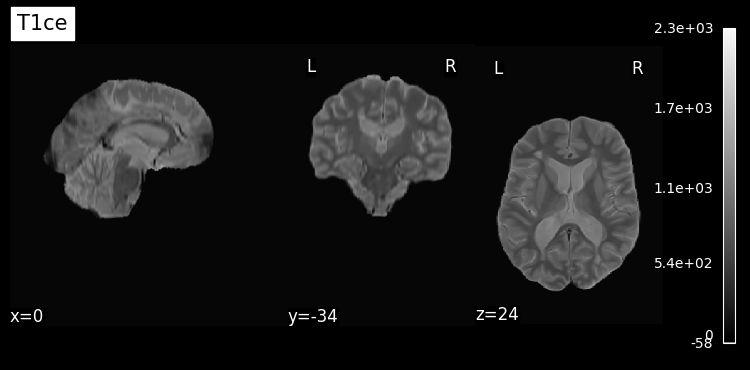

In [8]:
plotting.plot_anat(T1ce,title="T1ce",draw_cross =False)

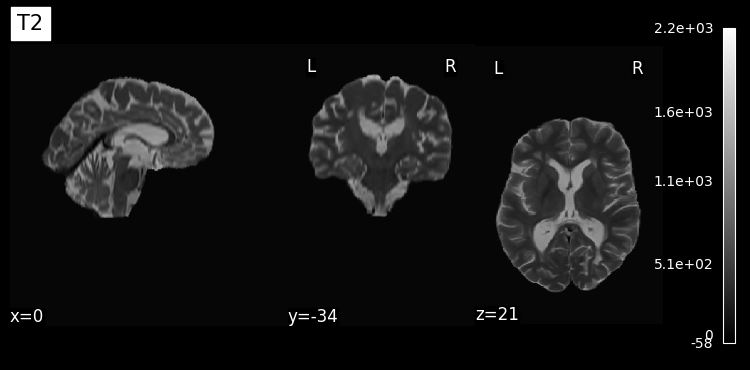

In [9]:
plotting.plot_anat(T2,title="T2",draw_cross =False)

# 3.Data Preprocessing

In [10]:
p=os.listdir(Path)
p[:8]

['MSSEG2016_TrainingData_Patient_03',
 'MSSEG2016_TrainingData_Patient_10',
 'MSSEG2016_TrainingData_Patient_06',
 'MSSEG2016_TrainingData_Patient_07',
 'MSSEG2016_TrainingData_Patient_02',
 'MSSEG2016_TrainingData_Patient_08',
 'MSSEG2016_TrainingData_Patient_04',
 'MSSEG2016_TrainingData_Patient_09']

In [11]:
Input_Data= []
def Data_Preprocessing(modalities_dir):
    all_modalities = []
    for modality in modalities_dir:
        nifti_file   = nib.load(modality)
        brain_numpy  = np.asarray(nifti_file.dataobj)
        all_modalities.append(brain_numpy)
    brain_affine   = nifti_file.affine
    all_modalities = np.array(all_modalities)
    all_modalities = np.rint(all_modalities).astype(np.int16)
    all_modalities = all_modalities[:, :, :, :]
    all_modalities = np.transpose(all_modalities)
    return all_modalities
for i in p[:6]:
    brain_dir = os.path.normpath(Path+'/'+i)
    flair     = glob.glob(os.path.join(brain_dir, '*_FLAIR*.nii'))
    t1        = glob.glob(os.path.join(brain_dir, '*_T1*.nii'))
    t1ce      = glob.glob(os.path.join(brain_dir, '*_DP*.nii'))
    t2        = glob.glob(os.path.join(brain_dir, '*_T2*.nii'))
    gt        = glob.glob( os.path.join(brain_dir, '*_Consensus*.nii'))
    modalities_dir = [flair[0], t1[0], t1ce[0], t2[0], gt[0]]
    P_Data = Data_Preprocessing(modalities_dir)
    Input_Data.append(P_Data)

In [12]:
def Data_Concatenate(Input_Data):
    counter=0
    Output= []
    for i in range(5):
        print('$')
        c=0
        counter=0
        for ii in range(len(Input_Data)):
            if (counter != len(Input_Data)):
                a= Input_Data[counter][:,:,:,i]
                #print('a={}'.format(a.shape))
                b= Input_Data[counter+1][:,:,:,i]
                #print('b={}'.format(b.shape))
                if(counter==0):
                    c= np.concatenate((a, b), axis=0)
                    print('c1={}'.format(c.shape))
                    counter= counter+2
                else:
                    c1= np.concatenate((a, b), axis=0)
                    c= np.concatenate((c, c1), axis=0)
                    print('c2={}'.format(c.shape))
                    counter= counter+2
        c= c[:,:,:,np.newaxis]
        Output.append(c)
    return Output

In [13]:
InData= Data_Concatenate(Input_Data)

$
c1=(1024, 256, 240)
c2=(2048, 256, 240)
c2=(3072, 256, 240)
$
c1=(1024, 256, 240)
c2=(2048, 256, 240)
c2=(3072, 256, 240)
$
c1=(1024, 256, 240)
c2=(2048, 256, 240)
c2=(3072, 256, 240)
$
c1=(1024, 256, 240)
c2=(2048, 256, 240)
c2=(3072, 256, 240)
$
c1=(1024, 256, 240)
c2=(2048, 256, 240)
c2=(3072, 256, 240)


In [14]:
del Input_Data

In [15]:
AIO= concatenate(InData, axis=3)
AIO=np.array(AIO,dtype='float32')
TR=np.array(AIO[:,:,:,1],dtype='float32')
TRL=np.array(AIO[:,:,:,4],dtype='float32')

In [16]:
X_train , X_test, Y_train, Y_test = train_test_split(TR, TRL, test_size=0.15, random_state=32)
AIO=TRL=0

In [17]:
def bn_act(x, act=True):
    x = keras.layers.BatchNormalization()(x)
    if act == True:
        x = keras.layers.Activation("relu")(x)
    return x

def conv_block(x, filters, kernel_size=(3, 3), padding="same", strides=1):
    conv = bn_act(x)
    conv = keras.layers.Conv2D(filters, kernel_size, padding=padding, strides=strides)(conv)
    return conv

def stem(x, filters, kernel_size=(3, 3), padding="same", strides=1):
    conv = keras.layers.Conv2D(filters, kernel_size, padding=padding, strides=strides)(x)
    conv = conv_block(conv, filters, kernel_size=kernel_size, padding=padding, strides=strides)

    shortcut = keras.layers.Conv2D(filters, kernel_size=(1, 1), padding=padding, strides=strides)(x)
    shortcut = bn_act(shortcut, act=False)

    output = keras.layers.Add()([conv, shortcut])
    return output

def residual_block(x, filters, kernel_size=(3, 3), padding="same", strides=1):
    res = conv_block(x, filters, kernel_size=kernel_size, padding=padding, strides=strides)
    res = conv_block(res, filters, kernel_size=kernel_size, padding=padding, strides=1)

    shortcut = keras.layers.Conv2D(filters, kernel_size=(1, 1), padding=padding, strides=strides)(x)
    shortcut = bn_act(shortcut, act=False)

    output = keras.layers.Add()([shortcut, res])
    return output

def upsample_concat_block(x, xskip):
    u = keras.layers.UpSampling2D((2, 2))(x)
    c = keras.layers.Concatenate()([u, xskip])
    return c

In [18]:
def ResUNet():
    f = [16, 32, 64, 128, 256]
    inputs = keras.layers.Input((256,240,1))

    ## Encoder
    e0 = inputs
    e1 = stem(e0, f[0])
    e2 = residual_block(e1, f[1], strides=2)
    e3 = residual_block(e2, f[2], strides=2)
    e4 = residual_block(e3, f[3], strides=2)
    e5 = residual_block(e4, f[4], strides=2)

    ## Bridge
    b0 = conv_block(e5, f[4], strides=1)
    b1 = conv_block(b0, f[4], strides=1)

    ## Decoder
    u1 = upsample_concat_block(b1, e4)
    d1 = residual_block(u1, f[4])

    u2 = upsample_concat_block(d1, e3)
    d2 = residual_block(u2, f[3])

    u3 = upsample_concat_block(d2, e2)
    d3 = residual_block(u3, f[2])

    u4 = upsample_concat_block(d3, e1)
    d4 = residual_block(u4, f[1])

    outputs = keras.layers.Conv2D(1, (1, 1), padding="same", activation="sigmoid")(d4)
    model = keras.models.Model(inputs, outputs)
    return model

In [19]:
model = ResUNet()
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 256, 240,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 256, 240,  │        160 │ input_layer[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 256, 240,  │         64 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 256, 240,  │          0 │ batch_normalizat… │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 256, 240,  │         32 │ input_layer[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 256, 240,  │      2,320 │ activation[0][0]  │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 240,  │         64 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 256, 240,  │          0 │ conv2d_1[0][0],   │
│                     │ 16)               │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 240,  │         64 │ add[0][0]         │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 256, 240,  │          0 │ batch_normalizat… │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 128, 120,  │      4,640 │ activation_1[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 120,  │        128 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 128, 120,  │        544 │ add[0][0]         │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 128, 120,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 120,  │        128 │ conv2d_5[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 128, 120,  │      9,248 │ activation_2[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 128, 120,  │          0 │ batch_normalizat

 Total params: 4,722,737 (18.02 MB)

 Trainable params: 4,715,441 (17.99 MB)

 Non-trainable params: 7,296 (28.50 KB)

In [20]:
# Computing Dice_Coefficient
def dice_coef(y_true, y_pred, smooth=1.0):
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (K.sum(y_true_f) + K.sum(y_pred_f) + smooth)

# Computing Precision
def precision(y_true, y_pred):
        true_positives = K.sum(K.round(K.clip(y_true * y_pred, 0, 1)))
        predicted_positives = K.sum(K.round(K.clip(y_pred, 0, 1)))
        precision = true_positives / (predicted_positives + K.epsilon())
        return precision

# Computing Sensitivity
def sensitivity(y_true, y_pred):
    true_positives = K.sum(K.round(K.clip(y_true * y_pred, 0, 1)))
    possible_positives = K.sum(K.round(K.clip(y_true, 0, 1)))
    return true_positives / (possible_positives + K.epsilon())

# Computing Specificity
def specificity(y_true, y_pred):
    true_negatives = K.sum(K.round(K.clip((1-y_true) * (1-y_pred), 0, 1)))
    possible_negatives = K.sum(K.round(K.clip(1-y_true, 0, 1)))
    return true_negatives / (possible_negatives + K.epsilon())

In [21]:
Adam=optimizers.Adam(learning_rate=0.001)

In [22]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy', dice_coef],
    jit_compile=False
)

In [23]:
history = model.fit(
    X_train,
    Y_train,
    batch_size=32,
    epochs=40,
    validation_split=0.20,
    verbose=1,
    initial_epoch=0
)

Epoch 1/40
66/66 ━━━━━━━━━━━━━━━━━━━━ 138s 1s/step - accuracy: 0.9875 - dice_coef: 0.0037 - loss: 0.0371 - val_accuracy: 0.9997 - val_dice_coef: 1.9907e-04 - val_loss: 0.0077
Epoch 2/40
66/66 ━━━━━━━━━━━━━━━━━━━━ 83s 1s/step - accuracy: 0.9997 - dice_coef: 0.0092 - loss: 0.0018 - val_accuracy: 0.9997 - val_dice_coef: 8.1988e-04 - val_loss: 0.0051
Epoch 3/40
66/66 ━━━━━━━━━━━━━━━━━━━━ 83s 1s/step - accuracy: 0.9997 - dice_coef: 0.0206 - loss: 0.0016 - val_accuracy: 0.9997 - val_dice_coef: 0.0069 - val_loss: 0.0021
Epoch 4/40
66/66 ━━━━━━━━━━━━━━━━━━━━ 83s 1s/step - accuracy: 0.9997 - dice_coef: 0.0664 - loss: 0.0014 - val_accuracy: 0.9997 - val_dice_coef: 0.0282 - val_loss: 0.0017
Epoch 5/40
66/66 ━━━━━━━━━━━━━━━━━━━━ 83s 1s/step - accuracy: 0.9997 - dice_coef: 0.0827 - loss: 0.0014 - val_accuracy: 0.9997 - val_dice_coef: 0.0061 - val_loss: 0.0023
Epoch 6/40
66/66 ━━━━━━━━━━━━━━━━━━━━ 83s 1s/step - accuracy: 0.9997 - dice_coef: 0.1321 - loss: 0.0012 - val_accuracy: 0.9997 - val_dice_coe

In [24]:
# Accuracy vs Epoch
def Accuracy_Graph(history):
    plt.plot(history.history['accuracy'])
    plt.plot(history.history['val_accuracy'])
    #plt.title('Model accuracy')
    plt.ylabel('Accuracy')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Validation'], loc='upper left')
    plt.subplots_adjust(top=1.00, bottom=0.0, left=0.0, right=0.95, hspace=0.25,
                        wspace=0.35)
    plt.show()

# Dice Similarity Coefficient vs Epoch
def Dice_coefficient_Graph(history):

    plt.plot(history.history['dice_coef'])
    plt.plot(history.history['val_dice_coef'])
    #plt.title('Dice_Coefficient')
    plt.ylabel('Dice_Coefficient')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Validation'], loc='upper left')
    plt.subplots_adjust(top=1.00, bottom=0.0, left=0.0, right=0.95, hspace=0.25,
                        wspace=0.35)
    plt.show()
# Loss vs Epoch
def Loss_Graph(history):

    plt.plot(history.history['loss'])
    plt.plot(history.history['val_loss'])
    #plt.title('Model loss')
    plt.ylabel('Loss')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Validation'], loc='upper left')
    plt.subplots_adjust(top=1.00, bottom=0.0, left=0.0, right=0.95, hspace=0.25,
                        wspace=0.35)
    plt.show()

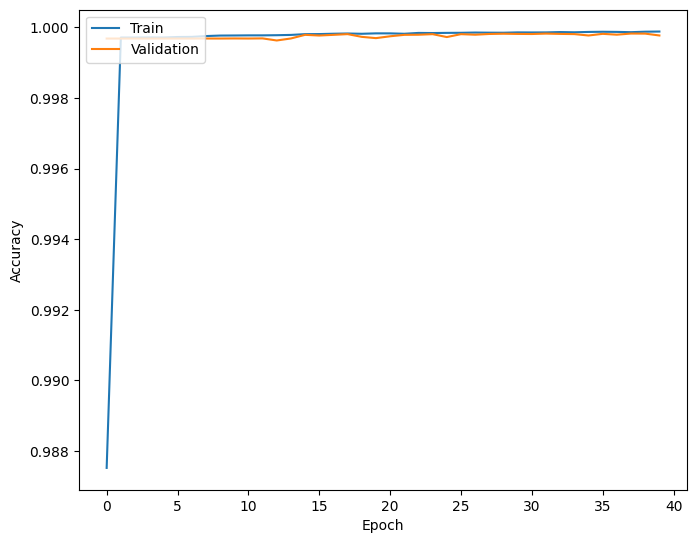

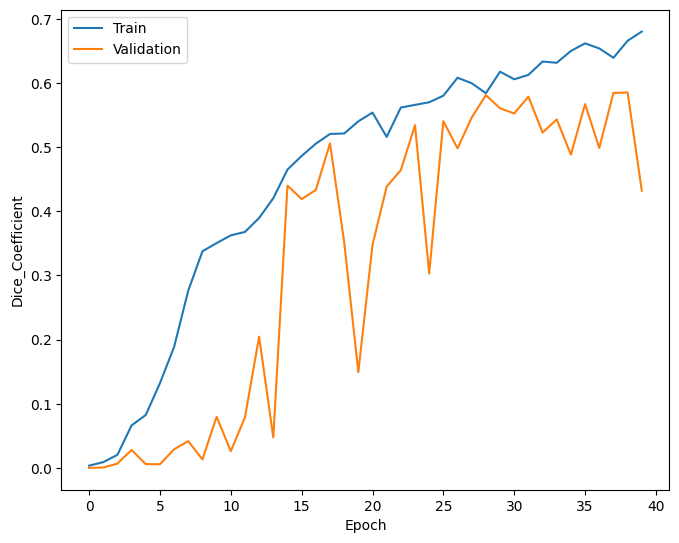

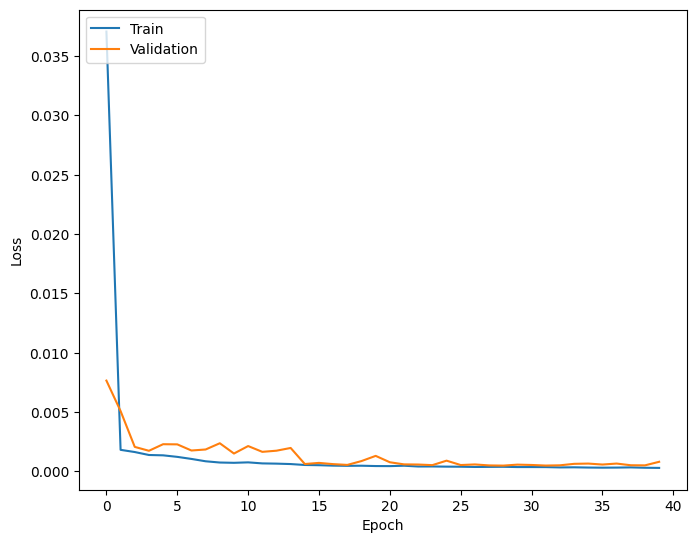

In [25]:
# Plotting the Graphs of Accuracy, Dice_coefficient, Loss at each epoch on Training and Testing data
Accuracy_Graph(history)
Dice_coefficient_Graph(history)
Loss_Graph(history)

In [26]:
model.save('./ms01.h5')

In [27]:
X_train=X_test=Y_train=Y_test=0

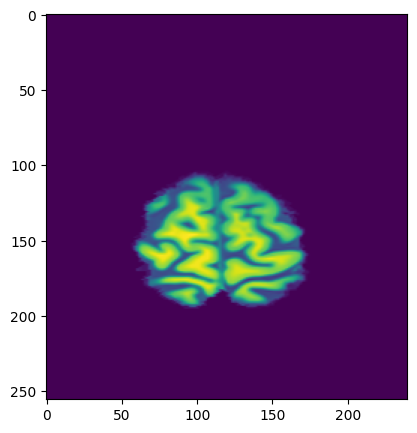

In [28]:
fig = plt.figure(figsize=(5,5))
immmg = TR[400,:,:]
imgplot = plt.imshow(immmg)
plt.show()

In [29]:
pref_Tumor = model.predict(TR)

96/96 ━━━━━━━━━━━━━━━━━━━━ 29s 295ms/step


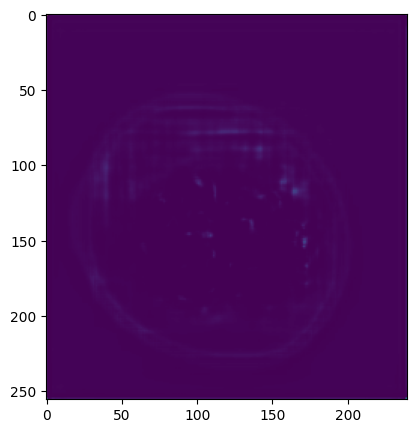

In [30]:
fig = plt.figure(figsize=(5,5))
immmg = pref_Tumor[400,:,:,0]
imgplot = plt.imshow(immmg)
plt.show()

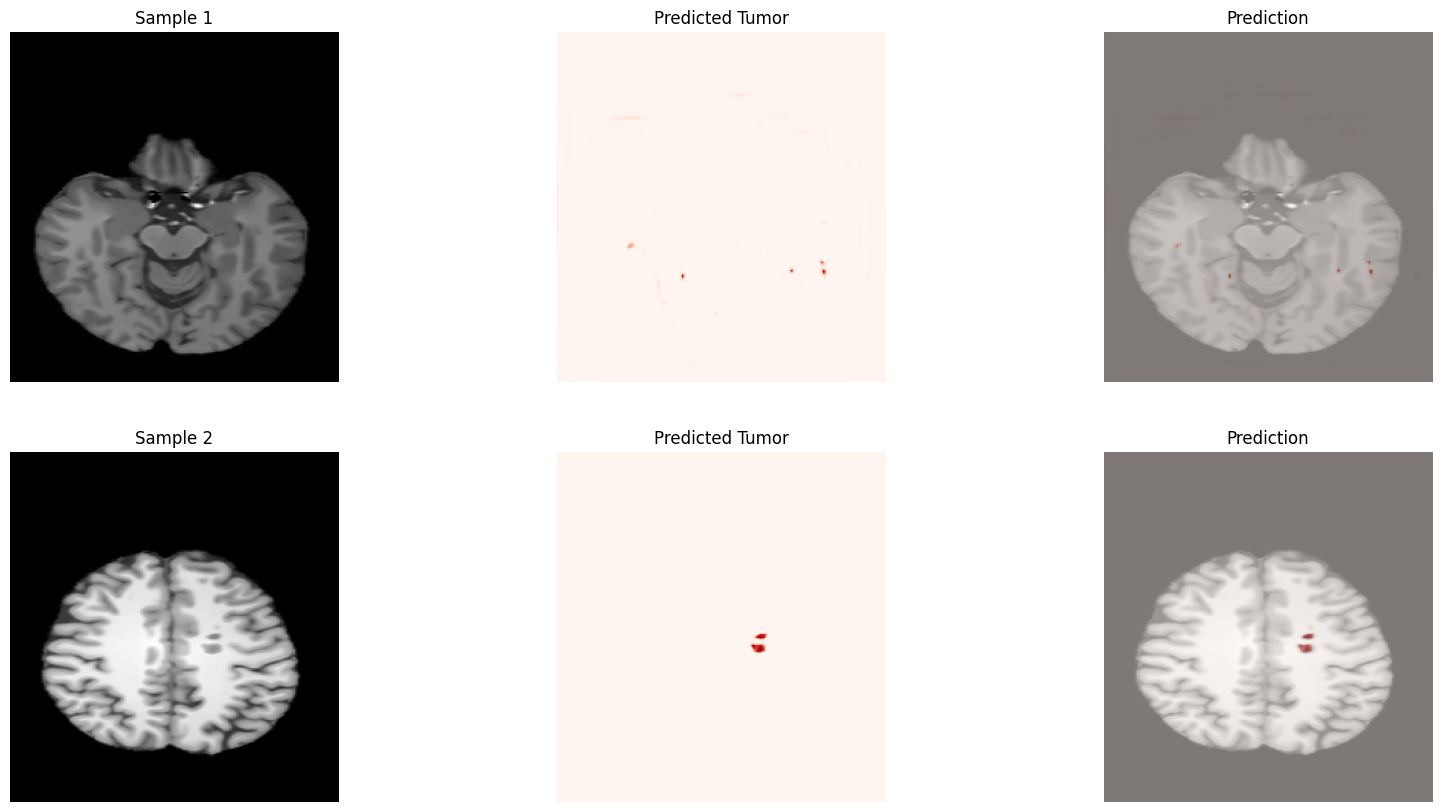

In [31]:
plt.figure(figsize=(20,10))


plt.subplot(231)
plt.title('Sample 1')
plt.axis('off')
plt.imshow(np.squeeze(TR[250,:,:]),cmap='gray')


plt.subplot(232)
plt.title('Predicted Tumor')
plt.axis('off')
plt.imshow(np.squeeze(pref_Tumor[250,:,:]),cmap='Reds')

plt.subplot(233)
plt.title('Prediction')
plt.axis('off')
plt.imshow(np.squeeze(TR[250,:,:]),cmap='gray')
plt.imshow(np.squeeze(pref_Tumor[250,:,:]),alpha = 0.5,cmap='Reds')


plt.subplot(234)
plt.title('Sample 2')
plt.axis('off')
plt.imshow(np.squeeze(TR[350,:,:]),cmap='gray')


plt.subplot(235)
plt.title('Predicted Tumor')
plt.axis('off')
plt.imshow(np.squeeze(pref_Tumor[350,:,:]),cmap='Reds')

plt.subplot(236)
plt.title('Prediction')
plt.axis('off')
plt.imshow(np.squeeze(TR[350,:,:]),cmap='gray')
plt.imshow(np.squeeze(pref_Tumor[350,:,:]),alpha = 0.5, cmap='Reds')